In [7]:
import numpy as np
import matplotlib.pyplot as plt
from pynwb import NWBHDF5IO
import pandas as pd
import h5py
import spikeinterface.full as si
from pynwb import NWBHDF5IO
from pynwb import read_nwb

file_path= "/Users/Zita/Documents/EGYETEM/Önlab/yolo26/Rat01_Insertion2_Depth2.nwb"
nwbfile = read_nwb(file_path)


sorting = si.read_nwb_sorting(file_path)
nwbfile


root pynwb.file.NWBFile at 0x4903315664
Fields:
  acquisition: {
    wideband_multichannel_recording <class 'pynwb.ecephys.ElectricalSeries'>
  }
  data_collection: Data was collected with a 128-site high-density silicon probe using the Intan RHD2000 electrophysiological recording system. Wideband signals (0.1  7500 Hz) were acquired with 20 kHz/channel sampling rate and with 16-bit resolution. On average, two insertions were made in a single animal and extracellular electrical activity was acquired from 2-3 cortical depths for ~30 minutes at each recording position. Spike sorting was performed on the acquired wideband data using Kilosort2. Several properties of the sorted single units as well as various spike sorting quality metrics are provided.
  devices: {
    Probe_D09_R13 <class 'pynwb.device.Device'>
  }
  electrode_groups: {
    Probe_D09_R13 <class 'pynwb.ecephys.ElectrodeGroup'>
  }
  electrodes: electrodes <class 'pynwb.ecephys.ElectrodesTable'>
  experiment_description: Spontaneously occurring slow-wave activity (local field potentials and extracellular spiking activity) from multiple layers of the neocortex of rats anesthetized with ketamine/xylazine.
  experimenter: [b'Csaba Horv\xe1th, Lili Fanni T\xf3th, Istv\xe1n Ulbert, Rich\xe1rd Fi\xe1th']
  file_create_date: [datetime.datetime(2021, 3, 16, 16, 9, 53, 497000, tzinfo=tzoffset(None, 3600))]
  identifier: Rat01_Insertion2_Depth2
  institution: Institute of Cognitive Neuroscience and Psychology, Research Centre for Natural Sciences, Budapest, Hungary
  keywords: <HDF5 dataset "keywords": shape (7,), type "|O">
  lab: Integrative Neuroscience Group (UlbertLab)
  pharmacology: The rat was anesthetized by an intramuscular or intraperitoneal injection of a mixture of ketamine (75 mg/kg of body weight) and xylazine (10 mg/kg of body weight). To maintain the depth of anesthesia during surgery and recordings, and to sustain the ongoing cortical slow-wave activity, supplementary intramuscular injections were given to the rats regularly using the same anesthetic cocktail.
  related_publications: [b'Publication related to the silicon probe: Fiath et al. (2018) "A silicon-based neural probe with densely-packed low-impedance titanium nitride microelectrodes for ultrahigh-resolution in vivo recordings." Biosensors and Bioelectronics 106: 86-92. DOI: 10.1016/j.bios.2018.01.060']
  session_description: Acute recording from the neocortex of a ketamine/xylazine-anesthetized rat using a 128-site high-density probe, and spike sorting results.
  session_id: Rat01_Insertion2_Depth2
  session_start_time: 2017-09-11 17:05:23+02:00
  subject: subject pynwb.file.Subject at 0x4898983312
Fields:
  description: strain: Wistar
  genotype: Wild type
  sex: F
  species: Rattus norvegicus
  subject_id: Rat01
  weight: 320 g

  surgery: The rat was anesthetized with ketamine/xylazine, placed in a stereotaxic frame, then a small craniotomy was drilled over the target cortical area. After puncturing the dura mater, the recording probe was inserted into the brain tissue with a slow speed.
  timestamps_reference_time: 2017-09-11 17:05:23+02:00
  units: units <class 'pynwb.misc.Units'>

In [3]:
import numpy as np
import os
from pynwb import NWBHDF5IO
import spikeinterface.full as si

io = NWBHDF5IO(file_path, "r")
nwb = io.read()
units_df = nwb.units.to_dataframe()
es = list(nwb.acquisition.values())[0]
print("conversion:", es.conversion)
print("offset:", es.offset)
print("unit:", es.unit)
print("resolution:", es.resolution)
io.close()


recording = si.read_nwb(file_path)
recording.set_channel_gains([0.195] * recording.get_num_channels())
recording.set_channel_offsets([0.0] * recording.get_num_channels())
recording = si.bandpass_filter(recording, 300, 6000)
recording = si.common_reference(recording, reference="global", operator="median")

total_frames = recording.get_num_frames()
fs = recording.get_sampling_frequency()
num_channels = recording.get_num_channels()
num_frames = recording.get_num_frames()

train_end = int(total_frames * 0.70)
val_end = train_end + int(total_frames * 0.15)

splits = {
    "train": (0, train_end),
    "val": (train_end, val_end),
    "test": (val_end, total_frames),
}


duration = num_frames / fs

print(f"Sampling frequency : {fs:.0f} Hz")
print(f"Channels           : {num_channels}")
print(f"Frames             : {num_frames}")
print(f"Duration           : {duration:.1f} s")

channel_locations = recording.get_channel_locations()

print(f"Channel locations shape   : {channel_locations.shape}")

channel_order = np.lexsort((channel_locations[:,0], -channel_locations[:,1]))
print(channel_order)

conversion: 0.195
offset: 0.0
unit: volts
resolution: 0.195
Sampling frequency : 20000 Hz
Channels           : 128
Frames             : 47854800
Duration           : 2392.7 s
Channel locations shape   : (128, 2)
[  0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17
  18  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35
  36  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53
  54  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71
  72  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89
  90  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106 107
 108 109 110 111 112 113 114 115 116 117 118 119 120 121 122 123 124 125
 126 127]


In [17]:
#CREATE EVENTS ARRAY
import spikeinterface.full
unit_ids = units_df.index.to_numpy()
unit_to_class = {unit_id: class_id for class_id, unit_id in enumerate(unit_ids)}
total = 0
events = []

for class_id, unit_id in enumerate(unit_ids):
    spike_frames = sorting.get_unit_spike_train(unit_id)
    peak_channel = int(units_df.loc[unit_id, "peak_waveform_channel"])

    for frame in spike_frames:
        events.append((int(frame), class_id, peak_channel))

events = np.asarray(events, dtype=np.int64)
events = events[np.argsort(events[:, 0])]

print(events.shape)
print(events[:10])  # Print the first 10 events for inspection


(725418, 3)
[[4124   66   96]
 [4514   66   96]
 [4716   56   81]
 [4787   69   97]
 [4792   50   69]
 [4799   56   81]
 [4817   90   89]
 [4903   59   81]
 [4907   50   69]
 [4921   51   72]]


In [18]:
import numpy as np

def build_windows(chunk, w_start, window_size, clip_low, clip_high):
    x = chunk[w_start:w_start + window_size, :]
    x = np.clip(x, clip_low, clip_high)
    x = (x - clip_low) / (clip_high - clip_low)
    x = (x * 255).astype(np.uint8)
    return x.T

def make_labels(win_events, window_start, window_size, num_channels=128):
    labels = []
    for frame, class_id, peak_channel in win_events:
        x_center = (frame - window_start) / window_size
        y_center = peak_channel / num_channels
        w, h = 0.06, 0.10  # fixed box size
        labels.append([class_id, x_center, y_center, w, h])
        
    return np.array(labels, dtype=np.float32)

In [19]:
import numpy as np
import os
import cv2
from tqdm import tqdm

sample = recording.get_traces(start_frame=0, end_frame=min(int(fs * 60), total_frames),
                               return_scaled=True)
scale_mean = sample.mean()
scale_std = sample.std()
clip_low = scale_mean - 6 * scale_std
clip_high = scale_mean + 6 * scale_std

def build_dataset(recording, events, splits, save_dir,
                  window_size=128, stride=64,
                  num_channels=128, neg_ratio=0.5, clip_low=None, clip_high=None):

    os.makedirs(save_dir, exist_ok=True)

    for split in splits:
        os.makedirs(f"{save_dir}/images/{split}", exist_ok=True)
        os.makedirs(f"{save_dir}/labels/{split}", exist_ok=True)

    frames = events[:, 0]
    fs = recording.get_sampling_frequency()
    chunk_size = int(30 * fs)

    for split, (split_start, split_end) in splits.items():
        file_id = 0
        pos_count = 0
        neg_count = 0

        for chunk_start in tqdm(range(split_start, split_end, chunk_size), desc= split): #progress bar
            chunk_end = min(chunk_start + chunk_size, split_end)
            read_end= min(chunk_end + 64, split_end) # read extra 64 frames for the last window

            chunk = recording.get_traces(start_frame=chunk_start, end_frame=read_end, return_scaled=True)[:, :num_channels]

            left = np.searchsorted(frames, chunk_start)
            right = np.searchsorted(frames, read_end)
            chunk_events = events[left:right]

            # SLIDING WINDOWS
            core_length = chunk_end - chunk_start
            for w_start in range(0, core_length - window_size + 1, stride):

                global_start = chunk_start + w_start
                global_end = global_start + window_size

                # events in window
                l = np.searchsorted(chunk_events[:, 0], global_start)
                r = np.searchsorted(chunk_events[:, 0], global_end)
                win_events = chunk_events[l:r]

                # WINDOW
                img = build_windows(chunk, w_start, window_size, clip_low=-100, clip_high=100)

                # LABELS
                labels = make_labels(win_events, global_start, window_size, num_channels)

                # NEGATIVE
                if len(labels) == 0:
                    if neg_count >= pos_count*neg_ratio:
                        continue
                    neg_count += 1
                else:
                    pos_count += 1

                # SAVE
                name = f"{split}_{file_id:07d}_f{global_start}"
                cv2.imwrite(f"{save_dir}/images/{split}/{name}.png", img)

                label_path = f"{save_dir}/labels/{split}/{name}.txt"
                with open(label_path, "w") as f:
                    for row in labels:
                        f.write(f"{int(row[0])} {row[1]:.6f} {row[2]:.6f} {row[3]:.6f} {row[4]:.6f}\n")

                file_id += 1

        print(f"{split} DONE → POS:{pos_count} NEG:{neg_count} (total {file_id})")
    

build_dataset(recording, events, splits, save_dir="dataset", window_size=128, stride=64, num_channels=128, neg_ratio=1.0)

KeyboardInterrupt: 

In [20]:
def sanity_check(events, window_size, num_channels):
    print("Total events:", len(events))
    print("Time range:", events[:, 0].min(), "→", events[:, 0].max())

    # spikes per neuron
    unique, counts = np.unique(events[:, 1], return_counts=True)
    print("Units:", len(unique))
    print("Max spikes/unit:", counts.max())
    print("Min spikes/unit:", counts.min())

    # channel distribution
    print("Channel range:", events[:, 2].min(), "→", events[:, 2].max())

    # window size compatibility
    assert window_size > 0
    assert num_channels > 0

sanity_check(events, window_size=128, num_channels=128)

Total events: 725418
Time range: 4124 → 47854609
Units: 100
Max spikes/unit: 38455
Min spikes/unit: 107
Channel range: 8 → 123


In [21]:
import numpy as np
img = cv2.imread("/Users/Zita/Documents/EGYETEM/Önlab/yolo26/dataset/images/train/train_0000000_f4032.png", cv2.IMREAD_GRAYSCALE)  # adjust filename
print("min:", img.min(), "max:", img.max(), "mean:", img.mean(), "std:", img.std())
print("per-channel mean range:", sample.mean(axis=0).min(), "to", sample.mean(axis=0).max())
print("global std:", sample.std())
print("per-channel std range:", sample.std(axis=0).min(), "to", sample.std(axis=0).max())

raw = recording.get_traces(start_frame=0, end_frame=1000, return_in_uV=False)
print("raw dtype:", raw.dtype, "raw range:", raw.min(), raw.max())


check = recording.get_traces(start_frame=0, end_frame=1000, return_in_uV=True)
print("corrected µV range:", check.min(), check.max())
print("images:", len(os.listdir("dataset/images/train")))
print("labels:", len(os.listdir("dataset/labels/train")))

min: 73 max: 160 mean: 126.93994140625 std: 6.176347777737809


NameError: name 'sample' is not defined

In [194]:
import json
with open("dataset_info.json", "w") as f:
    json.dump({"nc": len(unit_ids)}, f)

In [195]:
import os

train = len(os.listdir("dataset/images/train"))
val = len(os.listdir("dataset/images/val"))
test = len(os.listdir("dataset/images/test"))

print(train, val, test)

512041 112102 112100


In [218]:
#DATASET 2
MAX_SPIKES_PER_UNIT = 3000

balanced_events = []

for class_id, unit_id in enumerate(unit_ids):

    spike_frames = sorting.get_unit_spike_train(unit_id)

    peak_channel = int(units_df.loc[unit_id, "peak_waveform_channel"])
    cluster_id = int(units_df.loc[unit_id, "cluster_id"])

    # Cap large units
    if len(spike_frames) > MAX_SPIKES_PER_UNIT:
        idx = np.linspace(
            0,
            len(spike_frames) - 1,
            MAX_SPIKES_PER_UNIT,
            dtype=int
        )
        spike_frames = spike_frames[idx]

    for frame in spike_frames:
        balanced_events.append(
            (int(frame), class_id, peak_channel, cluster_id)
        )

balanced_events = np.asarray(balanced_events, dtype=np.int64)
balanced_events = balanced_events[np.argsort(balanced_events[:,0])]

print("Balanced events:", balanced_events.shape)


def sample_negative_centers(events,total_frames, n_negative, margin=256):
    frames = events[:,0]
    negatives = []
    while len(negatives) < n_negative:
        candidate = np.random.randint(margin,total_frames-margin)
        left = np.searchsorted(frames,candidate-margin)
        right = np.searchsorted(frames,candidate+margin)
        if left == right:
            negatives.append(candidate)

    return np.asarray(negatives)

def build_window(recording,center_frame, window_size, clip_low, clip_high):

    half = window_size // 2

    offset = np.random.randint(-24, 25)

    start = center_frame - half + offset
    end = start + window_size

    x = recording.get_traces(start_frame=start,end_frame=end,return_scaled=True)

    x = np.clip(x,clip_low,clip_high)

    x = (x-clip_low)/(clip_high-clip_low)

    x = (255*x).astype(np.uint8)

    return x.T


def make_labels(events, start_frame, end_frame, num_channels):

    labels = []

    inside = events[
        (events[:,0] >= start_frame) &
        (events[:,0] < end_frame)
    ]

    for frame, class_id, peak_channel, cluster in inside:

        xc = (frame-start_frame)/(end_frame-start_frame)
        yc = peak_channel/num_channels

        w = 6/(end_frame-start_frame)
        h = 6/num_channels

        labels.append(
            [class_id,
             xc,
             yc,
             w,
             h]
        )

    return np.asarray(labels)

Balanced events: (224822, 4)


In [ ]:
def build_window(chunk, window_start_local, window_size, clip_low, clip_high):

    x = chunk[window_start_local:window_start_local + window_size, :]
    x = np.clip(x, clip_low, clip_high)
    x = (x - clip_low) / (clip_high - clip_low)
    x = (255*x).astype(np.uint8)

    return x.T

def make_labels(win_events,window_start, window_size,num_channels=128):

    labels=[]

    for frame, class_id, peak_channel, cluster_id in win_events:

        x_center = (frame-window_start) / window_size
        y_center = (peak_channel / num_channels)

        # initial fixed bbox
        width = 0.06
        height = 0.10


        labels.append(
            [
                int(class_id),
                x_center,
                y_center,
                width,
                height
            ]
        )
    return labels

def sample_negative_centers(chunk_events,
                            chunk_start,
                            chunk_end,
                            n_samples,
                            margin=128):


    negatives=[]

    spike_frames = chunk_events[:,0]


    while len(negatives) < n_samples:

        candidate = np.random.randint(chunk_start+margin,chunk_end-margin)
        left = np.searchsorted(spike_frames,candidate-margin)
        right = np.searchsorted(spike_frames,candidate+margin)

        # no spike nearby

        if left == right:
            negatives.append(candidate)

    return np.array(negatives)

In [11]:
def create_dataset(recording,
                   events,
                   splits,
                   save_dir,
                   window_size=128,
                   negative_ratio=1.0,
                   chunk_sec=30):

    os.makedirs(save_dir, exist_ok=True)
    for split in splits:

        os.makedirs(f"{save_dir}/images/{split}", exist_ok=True)
        os.makedirs(f"{save_dir}/labels/{split}", exist_ok=True)

    fs = recording.get_sampling_frequency()

    chunk_size = int(chunk_sec * fs)
    num_channels = recording.get_num_channels()
    frames = events[:,0]

    file_counter = {
        "train":0,
        "val":0,
        "test":0
    }

    for split,(split_start,split_end) in splits.items():

        for chunk_start in tqdm(range(split_start,split_end,chunk_size)):

            chunk_end=min(chunk_start+chunk_size,split_end)

            chunk = recording.get_traces(
                start_frame=chunk_start,
                end_frame=chunk_end,
                return_scaled=True
            )

            chunk = chunk[:,:num_channels]

            left=np.searchsorted(frames, chunk_start)
            right=np.searchsorted(frames, chunk_end)
            chunk_events=events[left:right]

            if len(chunk_events)==0:
                continue

            # POSITIVE WINDOWS
            
            positive_centers = chunk_events[:,0]


            # NEGATIVE WINDOWS
            negative_centers = sample_negative_centers(
                chunk_events,
                chunk_start,
                chunk_end,
                int(len(positive_centers) * negative_ratio)
            )

            centers = list(zip(positive_centers,[1]*len(positive_centers)))
            centers += list(zip(negative_centers,[0]*len(negative_centers)))
            np.random.shuffle(centers)

            # Process windows

            for center,is_positive in centers:

                half = window_size//2
                # augmentation

                offset=np.random.randint(-24, 25)
                window_start = (center-half+offset)
                window_end = (window_start+window_size)

                # borders

                if window_start < chunk_start:
                    continue
                if window_end >= chunk_end:
                    continue

                local_start = (window_start-chunk_start)

                img = build_window(
                    chunk,
                    local_start,
                    window_size,
                    clip_low,
                    clip_high
                )

                # labels

                if is_positive:
                    l=np.searchsorted(chunk_events[:,0], window_start)
                    r=np.searchsorted(chunk_events[:,0], window_end)
                    win_events=chunk_events[l:r]
                    labels=make_labels(win_events, window_start, window_size, num_channels)

                else:
                    labels=[]

                # save
            
                idx=file_counter[split]
                name=f"{split}_{idx:07d}"
                cv2.imwrite(f"{save_dir}/images/{split}/{name}.png",img)

                with open(f"{save_dir}/labels/{split}/{name}.txt","w") as f:
                    for label in labels:

                        f.write(f"{label[0]} "
                            f"{label[1]:.6f} "
                            f"{label[2]:.6f} "
                            f"{label[3]:.6f} "
                            f"{label[4]:.6f}\n")
                file_counter[split]+=1

        print(
            split,
            "finished:",
            file_counter[split],
            "images"
        )

    print("\nDONE")

In [225]:
create_dataset(
    recording=recording,
    events=balanced_events,
    splits=splits,
    save_dir="dataset_test2",
    window_size=128,
    negative_ratio=1.0,
    chunk_sec=30
)


Processing train


  0%|          | 0/56 [00:00<?, ?it/s]/var/folders/q8/kt7cvxvj56q7t4t7txfsnz200000gq/T/ipykernel_87710/3998636311.py:68: DeprecationWarning: `return_scaled` is deprecated and will be removed in version 0.105.0. Use `return_in_uV` instead.
  chunk = recording.get_traces(
100%|██████████| 56/56 [09:54<00:00, 10.61s/it]


train finished: 293641 images

Processing val


100%|██████████| 12/12 [02:09<00:00, 10.83s/it]


val finished: 74781 images

Processing test


100%|██████████| 12/12 [02:07<00:00, 10.64s/it]

test finished: 81183 images

DONE


/var/folders/q8/kt7cvxvj56q7t4t7txfsnz200000gq/T/ipykernel_45746/989866024.py:7: DeprecationWarning: `return_scaled` is deprecated and will be removed in version 0.105.0. Use `return_in_uV` instead.
  sample = recording.get_traces(start_frame=0, end_frame=min(int(fs * 60), total_frames),
/var/folders/q8/kt7cvxvj56q7t4t7txfsnz200000gq/T/ipykernel_45746/989866024.py:15: DeprecationWarning: `return_scaled` is deprecated and will be removed in version 0.105.0. Use `return_in_uV` instead.
  bg_window = recording.get_traces(start_frame=w_start_frame, end_frame=w_start_frame + window_size, return_scaled=True)
/var/folders/q8/kt7cvxvj56q7t4t7txfsnz200000gq/T/ipykernel_45746/989866024.py:21: DeprecationWarning: `return_scaled` is deprecated and will be removed in version 0.105.0. Use `return_in_uV` instead.
  spike_window = recording.get_traces(start_frame=spike_w_start, end_frame=spike_w_start + window_size, return_scaled=True)


unique values in background window: 220
unique values in spike window: 213
clip range: -71.53222 71.04014
1st/99th percentile of sample: [-33.73500061  29.0549984 ]
spike: 0 255 125.422607421875 26.86127677673478
bg:    95 157 126.98895263671875 6.742305186306519


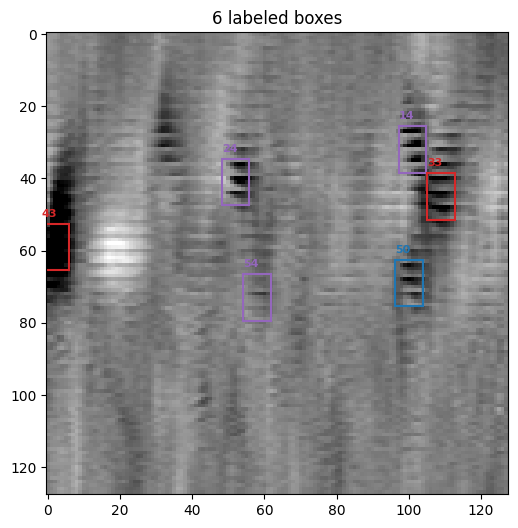

In [ ]:
"""""
w_start_frame = 0  # background window start, adjust as needed
 # or whatever spike frame you're using
unit_id = sorting.unit_ids[20]  # or whichever unit you want to inspect
spike_train = sorting.get_unit_spike_train(unit_id)
spike_frame = spike_train[20] 
window_size = 128
sample = recording.get_traces(start_frame=0, end_frame=min(int(fs * 60), total_frames),
                               return_scaled=True)
scale_mean = sample.mean()
scale_std = sample.std()
clip_low = scale_mean - 6 * scale_std
clip_high = scale_mean + 6 * scale_std

# background window
bg_window = recording.get_traces(start_frame=w_start_frame, end_frame=w_start_frame + window_size, return_scaled=True)
bg_window = np.clip(bg_window, clip_low, clip_high)
bg_window = ((bg_window - clip_low) / (clip_high - clip_low) * 255).astype(np.uint8)

# spike window
spike_w_start = spike_frame - window_size // 2
spike_window = recording.get_traces(start_frame=spike_w_start, end_frame=spike_w_start + window_size, return_scaled=True)
spike_window = np.clip(spike_window, clip_low, clip_high)
spike_window = ((spike_window - clip_low) / (clip_high - clip_low) * 255).astype(np.uint8)

print("unique values in background window:", len(np.unique(bg_window)))
print("unique values in spike window:", len(np.unique(spike_window)))

print("clip range:", clip_low, clip_high)
print("1st/99th percentile of sample:", np.percentile(sample, [1, 99]))
"""

import cv2

spike_img = cv2.imread("/Users/Zita/Documents/EGYETEM/Önlab/yolo26/dataset/images/train/train_0440335_f28908608.png", cv2.IMREAD_GRAYSCALE)
bg_img = cv2.imread("/Users/Zita/Documents/EGYETEM/Önlab/yolo26/dataset/images/train/train_0036961_f2480128.png", cv2.IMREAD_GRAYSCALE)

print("spike:", spike_img.min(), spike_img.max(), spike_img.mean(), spike_img.std())
print("bg:   ", bg_img.min(), bg_img.max(), bg_img.mean(), bg_img.std())

import matplotlib.patches as patches
img_path = "/Users/Zita/Documents/EGYETEM/Önlab/yolo26/dataset/images/train/train_0440335_f28908608.png"
label_path = "/Users/Zita/Documents/EGYETEM/Önlab/yolo26/dataset/labels/train/train_0440335_f28908608.txt"
img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
img_size = img.shape[0]
boxes = []
with open(label_path) as f:
    for line in f:
        parts = line.strip().split()
        class_id = int(parts[0])
        xc, yc, w, h = map(float, parts[1:5])
        boxes.append((class_id, xc, yc, w, h))

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(img, cmap="gray")

colors = plt.cm.tab10(np.linspace(0, 1, 10))  # cycle through 10 distinct colors

for i, (class_id, xc, yc, w, h) in enumerate(boxes):
    x0 = (xc - w / 2) * img_size
    y0 = (yc - h / 2) * img_size
    box_w = w * img_size
    box_h = h * img_size
    color = colors[class_id % 10]
    rect = patches.Rectangle((x0, y0), box_w, box_h, linewidth=1.5, edgecolor=color, facecolor='none')
    ax.add_patch(rect)
    ax.text(x0, y0 - 2, str(class_id), color=color, fontsize=8, weight='bold')

ax.set_title(f"{len(boxes)} labeled boxes")
plt.show()

In [31]:
import numpy as np
import matplotlib.pyplot as plt

# --- config ---
chunk_duration_s = 30          # analyze in 30s chunks
chunk_size = int(fs * chunk_duration_s)
n_chunks = total_frames // chunk_size

n_channels = recording.get_num_channels()

# storage: one row per chunk, one column per channel
chunk_mean = np.zeros((n_chunks, n_channels))
chunk_std  = np.zeros((n_chunks, n_channels))
chunk_p01  = np.zeros((n_chunks, n_channels))
chunk_p99  = np.zeros((n_chunks, n_channels))
chunk_time_s = np.zeros(n_chunks)

# --- scan the whole recording, chunk by chunk ---
for i in range(n_chunks):
    start = i * chunk_size
    end = start + chunk_size
    traces = recording.get_traces(start_frame=start, end_frame=end, return_scaled=True)  # (time, channels)

    chunk_mean[i] = traces.mean(axis=0)
    chunk_std[i]  = traces.std(axis=0)
    chunk_p01[i]  = np.percentile(traces, 1, axis=0)
    chunk_p99[i]  = np.percentile(traces, 99, axis=0)
    chunk_time_s[i] = start / fs

    if i % 20 == 0:
        print(f"chunk {i}/{n_chunks} ({chunk_time_s[i]:.0f}s)")

print("scan done")

/var/folders/q8/kt7cvxvj56q7t4t7txfsnz200000gq/T/ipykernel_45746/4080168061.py:22: DeprecationWarning: `return_scaled` is deprecated and will be removed in version 0.105.0. Use `return_in_uV` instead.
  traces = recording.get_traces(start_frame=start, end_frame=end, return_scaled=True)  # (time, channels)


chunk 0/79 (0s)
chunk 20/79 (600s)
chunk 40/79 (1200s)
chunk 60/79 (1800s)
scan done


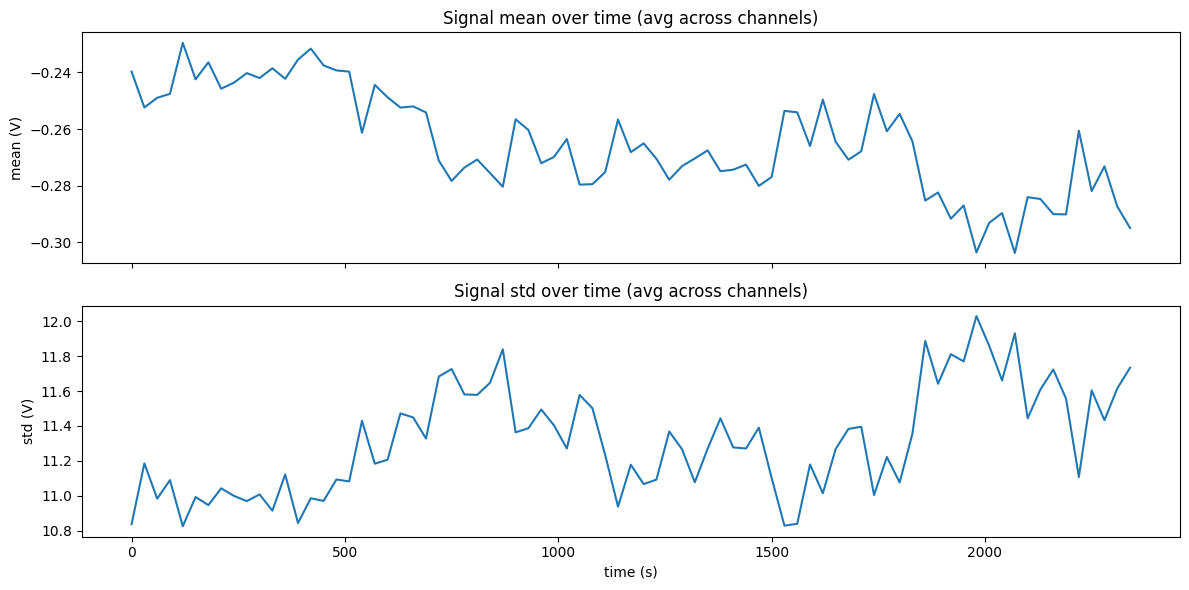

std range over time: 10.8262 to 12.0290 V
relative drift: 10.6%


In [32]:
# --- 1. drift over time: does std/mean change as the recording progresses? ---
mean_over_channels = chunk_mean.mean(axis=1)   # (n_chunks,) - avg channel mean per time chunk
std_over_channels  = chunk_std.mean(axis=1)    # (n_chunks,) - avg channel std per time chunk

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(chunk_time_s, mean_over_channels)
axes[0].set_ylabel("mean (V)")
axes[0].set_title("Signal mean over time (avg across channels)")

axes[1].plot(chunk_time_s, std_over_channels)
axes[1].set_ylabel("std (V)")
axes[1].set_xlabel("time (s)")
axes[1].set_title("Signal std over time (avg across channels)")
plt.tight_layout()
plt.show()

# quantify: how much does std drift relative to its own average?
drift_pct = (std_over_channels.max() - std_over_channels.min()) / std_over_channels.mean() * 100
print(f"std range over time: {std_over_channels.min():.4f} to {std_over_channels.max():.4f} V")
print(f"relative drift: {drift_pct:.1f}%")

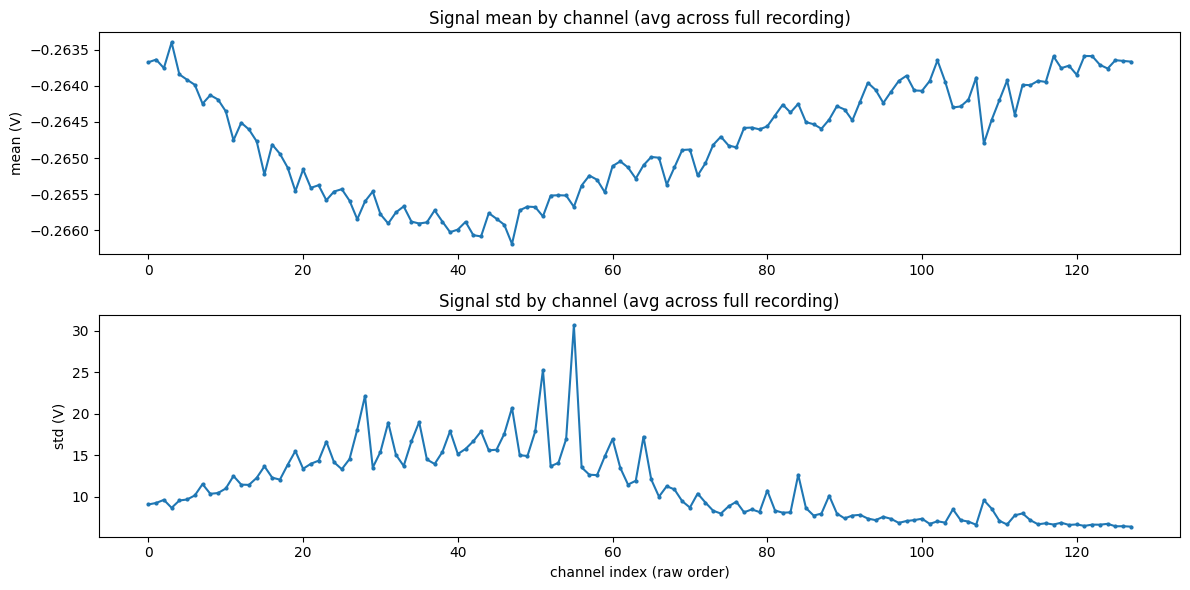

std range across channels: 6.3809 to 30.6551 V
relative channel-to-channel variation: 214.5%


In [33]:
# --- 2. variation across channels: do channels have meaningfully different noise floors? ---
mean_over_time = chunk_mean.mean(axis=0)  # (n_channels,) - avg over all chunks, per channel
std_over_time  = chunk_std.mean(axis=0)   # (n_channels,) - avg over all chunks, per channel

fig, axes = plt.subplots(2, 1, figsize=(12, 6))
axes[0].plot(mean_over_time, marker='o', markersize=2)
axes[0].set_ylabel("mean (V)")
axes[0].set_title("Signal mean by channel (avg across full recording)")

axes[1].plot(std_over_time, marker='o', markersize=2)
axes[1].set_ylabel("std (V)")
axes[1].set_xlabel("channel index (raw order)")
axes[1].set_title("Signal std by channel (avg across full recording)")
plt.tight_layout()
plt.show()

channel_variation_pct = (std_over_time.max() - std_over_time.min()) / std_over_time.mean() * 100
print(f"std range across channels: {std_over_time.min():.4f} to {std_over_time.max():.4f} V")
print(f"relative channel-to-channel variation: {channel_variation_pct:.1f}%")

In [35]:
import numpy as np

# --- denser sampling to cover the step-change around t~1850s ---
n_samples = 8
chunk_dur = int(fs * 30)  # 30s per sample point
sample_chunks = []

for frac in np.linspace(0.02, 0.98, n_samples):
    start = int(total_frames * frac)
    start = min(start, total_frames - chunk_dur)
    sample_chunks.append(recording.get_traces(start_frame=start, end_frame=start + chunk_dur, return_scaled=True))

sample = np.concatenate(sample_chunks, axis=0)  # (time, channels)
print("sample shape:", sample.shape)  # should be (n_samples * chunk_dur, n_channels)

# --- per-channel percentile clip range ---
clip_low = np.percentile(sample, 1, axis=0)   # shape: (n_channels,)
clip_high = np.percentile(sample, 99, axis=0) # shape: (n_channels,)

# --- sanity check prints ---
print("\nclip_low  - min: {:.3f}, max: {:.3f}, mean: {:.3f}".format(clip_low.min(), clip_low.max(), clip_low.mean()))
print("clip_high - min: {:.3f}, max: {:.3f}, mean: {:.3f}".format(clip_high.min(), clip_high.max(), clip_high.mean()))

clip_range = clip_high - clip_low
print("\nclip_range (per channel) - min: {:.3f}, max: {:.3f}, mean: {:.3f}".format(
    clip_range.min(), clip_range.max(), clip_range.mean()))

# which channels have the widest / narrowest range (should roughly match your std-by-channel plot)
widest = np.argsort(clip_range)[-5:][::-1]
narrowest = np.argsort(clip_range)[:5]
print("\nwidest-range channels (raw index):", widest, "-> ranges:", clip_range[widest])
print("narrowest-range channels (raw index):", narrowest, "-> ranges:", clip_range[narrowest])

/var/folders/q8/kt7cvxvj56q7t4t7txfsnz200000gq/T/ipykernel_45746/4221632143.py:11: DeprecationWarning: `return_scaled` is deprecated and will be removed in version 0.105.0. Use `return_in_uV` instead.
  sample_chunks.append(recording.get_traces(start_frame=start, end_frame=start + chunk_dur, return_scaled=True))


sample shape: (4800000, 128)

clip_low  - min: -77.220, max: -18.135, mean: -35.633
clip_high - min: 16.770, max: 64.740, mean: 29.338

clip_range (per channel) - min: 34.905, max: 141.960, mean: 64.972

widest-range channels (raw index): [28 47 31 35 27] -> ranges: [141.95999 125.96999 122.84999 117.38999 116.415  ]
narrowest-range channels (raw index): [127 126 125 119 107] -> ranges: [34.905    35.295    35.295    35.489998 35.684998]


In [36]:
import numpy as np
import cv2
import glob
import os

# --- config ---
img_dir = "/Users/Zita/Documents/EGYETEM/Önlab/yolo26/dataset_test2/images/train"
label_dir = "/Users/Zita/Documents/EGYETEM/Önlab/yolo26/dataset_test2/labels/train"
img_size = 128
contrast_std_threshold = 15   # local patch std above this = "high contrast" candidate
patch_size = 16               # sliding patch size for local contrast scan
stride = 8

img_paths = sorted(glob.glob(os.path.join(img_dir, "*.png")))
print(f"scanning {len(img_paths)} images")

def load_boxes(label_path, img_size):
    boxes = []
    if not os.path.exists(label_path):
        return boxes
    with open(label_path) as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) < 5:
                continue
            _, xc, yc, w, h = map(float, parts[:5])
            x0 = (xc - w / 2) * img_size
            y0 = (yc - h / 2) * img_size
            x1 = (xc + w / 2) * img_size
            y1 = (yc + h / 2) * img_size
            boxes.append((x0, y0, x1, y1))
    return boxes

def patch_overlaps_any_box(px0, py0, px1, py1, boxes):
    for (bx0, by0, bx1, by1) in boxes:
        # simple rectangle overlap check
        if px0 < bx1 and px1 > bx0 and py0 < by1 and py1 > by0:
            return True
    return False

n_images = 0
n_images_with_gap = 0
total_flagged_patches = 0

for img_path in img_paths:
    base = os.path.splitext(os.path.basename(img_path))[0]
    label_path = os.path.join(label_dir, base + ".txt")

    img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        continue
    boxes = load_boxes(label_path, img_size)

    n_images += 1
    found_gap_in_this_image = False

    for y in range(0, img_size - patch_size, stride):
        for x in range(0, img_size - patch_size, stride):
            patch = img[y:y + patch_size, x:x + patch_size]
            if patch.std() > contrast_std_threshold:
                if not patch_overlaps_any_box(x, y, x + patch_size, y + patch_size, boxes):
                    found_gap_in_this_image = True
                    total_flagged_patches += 1

    if found_gap_in_this_image:
        n_images_with_gap += 1

    if n_images % 500 == 0:
        print(f"scanned {n_images}/{len(img_paths)} images, {n_images_with_gap} with unlabeled high-contrast regions so far")

print("\n--- results ---")
print(f"total images scanned: {n_images}")
print(f"images with at least one unlabeled high-contrast patch: {n_images_with_gap} ({100*n_images_with_gap/n_images:.1f}%)")
print(f"total flagged patches: {total_flagged_patches}")

scanning 293641 images
scanned 500/293641 images, 342 with unlabeled high-contrast regions so far
scanned 1000/293641 images, 684 with unlabeled high-contrast regions so far
scanned 1500/293641 images, 1029 with unlabeled high-contrast regions so far
scanned 2000/293641 images, 1369 with unlabeled high-contrast regions so far
scanned 2500/293641 images, 1697 with unlabeled high-contrast regions so far
scanned 3000/293641 images, 2034 with unlabeled high-contrast regions so far
scanned 3500/293641 images, 2394 with unlabeled high-contrast regions so far
scanned 4000/293641 images, 2732 with unlabeled high-contrast regions so far
scanned 4500/293641 images, 3091 with unlabeled high-contrast regions so far
scanned 5000/293641 images, 3414 with unlabeled high-contrast regions so far
scanned 5500/293641 images, 3759 with unlabeled high-contrast regions so far
scanned 6000/293641 images, 4080 with unlabeled high-contrast regions so far
scanned 6500/293641 images, 4412 with unlabeled high-con

In [37]:
import numpy as np
import spikeinterface.full as si
import matplotlib.pyplot as plt

# --- get templates for all units ---
# if you already have templates computed (e.g. via si.compute_templates), reuse that.
# otherwise, compute them from the sorting + recording:

analyzer = si.create_sorting_analyzer(sorting, recording, sparse=False)
analyzer.compute("random_spikes", max_spikes_per_unit=200)
analyzer.compute("templates")

templates_ext = analyzer.get_extension("templates")
all_templates = templates_ext.get_data()  # shape: (n_units, n_samples, n_channels)

unit_ids = sorting.unit_ids
print("templates shape:", all_templates.shape)

# --- for each unit, find the peak channel and check the sign of its dominant deflection ---
results = []

for i, unit_id in enumerate(unit_ids):
    template = all_templates[i]  # (n_samples, n_channels)

    # find the channel with the largest absolute deviation (peak channel)
    peak_channel = np.argmax(np.max(np.abs(template), axis=0))
    waveform = template[:, peak_channel]

    max_val = waveform.max()
    min_val = waveform.min()

    # dominant deflection: whichever has greater absolute magnitude
    if abs(max_val) > abs(min_val):
        polarity = "positive"
        peak_amplitude = max_val
    else:
        polarity = "negative"
        peak_amplitude = min_val

    results.append({
        "unit_id": unit_id,
        "peak_channel": peak_channel,
        "polarity": polarity,
        "peak_amplitude": peak_amplitude,
        "max_val": max_val,
        "min_val": min_val,
    })

# --- summarize ---
n_positive = sum(1 for r in results if r["polarity"] == "positive")
n_negative = sum(1 for r in results if r["polarity"] == "negative")

print(f"\ntotal units: {len(results)}")
print(f"positive-going: {n_positive} ({100*n_positive/len(results):.1f}%)")
print(f"negative-going: {n_negative} ({100*n_negative/len(results):.1f}%)")

# list the positive-going units specifically, since that's the likely gap
positive_units = [r["unit_id"] for r in results if r["polarity"] == "positive"]
print("\npositive-going unit IDs:", positive_units)

/opt/anaconda3/envs/spike/lib/python3.11/site-packages/spikeinterface/core/baserecordingsnippets.py:259: UserWarning: There is no Probe attached to this recording. Creating a dummy one with contact positions
  warn("There is no Probe attached to this recording. Creating a dummy one with contact positions")


estimate_templates_with_accumulator (no parallelization):   0%|          | 0/2393 [00:00<?, ?it/s]

templates shape: (100, 60, 128)

total units: 100
positive-going: 0 (0.0%)
negative-going: 100 (100.0%)

positive-going unit IDs: []
